In [ ]:
#om ganeshay namah 
#waheguru  ji

In [1]:
# %% [markdown]
# ## 🚀 Step 2.1: Data Generation with Intentional Anomalies

import os
import random
import numpy as np
import pandas as pd

def generate_raw_dataset(num_rows=1500, output_path="data/raw_contracts.csv"):
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    np.random.seed(42)
    random.seed(42)
    
    data = []
    tech_stacks = ["Fullstack web", "frontend REACT", "backend python", "Mobile App", "DevOps", "Data engineering"]
    
    for i in range(num_rows):
        experience = min(int(np.random.exponential(scale=3)) + 1, 20)
        duration_days = random.randint(10, 180)
        base_budget = duration_days * (500 + (experience * 400))
        budget = int(base_budget * random.uniform(0.6, 1.5))
        tech_stack = random.choice(tech_stacks)
        
        # Ground Truth Risk Engine
        daily_rate = budget / duration_days
        risk_score = 0.0
        if daily_rate < 500: risk_score += 0.6
        if experience < 3 and duration_days > 90: risk_score += 0.4
        if budget < 15000: risk_score += 0.3
        
        risk_score += random.uniform(-0.2, 0.2)
        risk_label = 1 if risk_score > 0.45 else 0
        
        # Inject Anomaly A: Inconsistent/Messy Casing
        if random.random() < 0.3: tech_stack = tech_stack.lower()
        elif random.random() < 0.2: tech_stack = tech_stack.upper()
            
        # Inject Anomaly B: Out-of-bound / Negative values
        if random.random() < 0.05: budget = -budget
        if random.random() < 0.03: duration_days = -duration_days
            
        # Inject Anomaly C: NaNs
        budget_val = np.nan if random.random() < 0.05 else budget
        duration_val = np.nan if random.random() < 0.04 else duration_days
        experience_val = np.nan if random.random() < 0.03 else experience
        
        data.append({
            "contract_id": f"CON-{1000 + i}",
            "developer_experience_years": experience_val,
            "tech_stack_category": tech_stack,
            "duration_days": duration_val,
            "total_budget_inr": budget_val,
            "delivery_risk_label": risk_label
        })
        
    df = pd.DataFrame(data)
    # Inject Anomaly D: Explicit Row Duplicates
    duplicates = df.sample(n=30, random_state=42)
    df = pd.concat([df, duplicates], ignore_index=True)
    
    shuffled_df = df.sample(frac=1, random_state=42).reset_index(drop=True)
    shuffled_df.to_csv(output_path, index=False)
    print(f"✅ Generated anomaly-ridden dataset shape: {shuffled_df.shape}")

# Run generator
generate_raw_dataset()

# %% [markdown]
# ## 🧼 Step 2.2: Deep Data Scrubbing & Preprocessing Layer

def scrub_contract_data(input_path="data/raw_contracts.csv", output_path="data/cleaned_data.csv"):
    print("\n--- Starting Data Deep Scrubbing Layer ---")
    df = pd.read_csv(input_path)
    print(f"Initial Shape: {df.shape}")
    
    # 1. Row Deduplication
    initial_len = len(df)
    df = df.drop_duplicates(subset=["contract_id"], keep="first")
    print(f"🔄 Removed {initial_len - len(df)} duplicate rows.")
    
    # 2. Text Case Anomaly Normalization (Title Case Mapping)
    df["tech_stack_category"] = df["tech_stack_category"].fillna("Unknown").astype(str)
    df["tech_stack_category"] = df["tech_stack_category"].str.strip().str.title()
    print("🔤 Standardized tech stack strings to Title Case.")
    
    # 3. Out-of-Bound / Negative Metrics Conversion via Absolute Value Logic
    num_cols_to_abs = ["developer_experience_years", "duration_days", "total_budget_inr"]
    for col in num_cols_to_abs:
        if col in df.columns:
            neg_count = (df[col] < 0).sum()
            df[col] = df[col].abs()
            if neg_count > 0:
                print(f"🔢 Inverted {neg_count} negative anomalies to positive absolute values in '{col}'.")
                
    # 4. Robust Median Imputation Strategies for NaNs
    for col in num_cols_to_abs:
        nan_count = df[col].isna().sum()
        if nan_count > 0:
            median_val = df[col].median()
            df[col] = df[col].fillna(median_val)
            print(f"🩹 Imputed {nan_count} missing values in '{col}' with median: {median_val}")
            
    # Save the scrubbed artifact
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    df.to_csv(output_path, index=False)
    print(f"🎯 Scrubbing complete! Saved clean dataset shape {df.shape} to: '{output_path}'")
    return df

# Run scrubber
cleaned_df = scrub_contract_data()

# %% [markdown]
# ## 🔍 Step 2.3: Quick Sanity Verification Check

print("\n--- Sanity Inspection Check ---")
print(f"Any remaining missing values?:\n{cleaned_df.isna().sum()}\n")
print(f"Unique categories in Tech Stack:\n{cleaned_df['tech_stack_category'].unique()}")

✅ Generated anomaly-ridden dataset shape: (1530, 6)

--- Starting Data Deep Scrubbing Layer ---
Initial Shape: (1530, 6)
🔄 Removed 30 duplicate rows.
🔤 Standardized tech stack strings to Title Case.
🔢 Inverted 51 negative anomalies to positive absolute values in 'duration_days'.
🔢 Inverted 74 negative anomalies to positive absolute values in 'total_budget_inr'.
🩹 Imputed 36 missing values in 'developer_experience_years' with median: 3.0
🩹 Imputed 66 missing values in 'duration_days' with median: 97.0
🩹 Imputed 69 missing values in 'total_budget_inr' with median: 142144.0
🎯 Scrubbing complete! Saved clean dataset shape (1500, 6) to: 'data/cleaned_data.csv'

--- Sanity Inspection Check ---
Any remaining missing values?:
contract_id                   0
developer_experience_years    0
tech_stack_category           0
duration_days                 0
total_budget_inr              0
delivery_risk_label           0
dtype: int64

Unique categories in Tech Stack:
<ArrowStringArray>
[      'Mobile

In [3]:
# %% [markdown]
# ## 🤖 Step 3.1: Machine Learning Model Training Pipeline (Encoding Bug Fixed)

import os
import pickle
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

def train_delivery_risk_model(input_path="data/cleaned_data.csv", model_output_path="models/model.pkl"):
    print("\n--- Starting Machine Learning Training Pipeline ---")
    
    # 1. Load data
    if not os.path.exists(input_path):
        raise FileNotFoundError(f"Missing cleaned data! Please run the scrubbing cell first.")
    df = pd.read_csv(input_path)
    
    # 2. Separate Target and Features
    X = df[["developer_experience_years", "duration_days", "total_budget_inr"]]
    y = df["delivery_risk_label"]
    
    # 3. Train-Test Split (80% Train, 20% Test validation)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    print(f"📊 Training Matrix: {X_train.shape} | Testing Validation Matrix: {X_test.shape}")
    
    # 4. Initialize and Fit Random Forest Ensemble
    model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, class_weight="balanced")
    model.fit(X_train, y_train)
    
    # 5. Evaluate Model Quality
    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    
    print("\n🎯 Model Validation Evaluation Metrics:")
    print(f"Overall Accuracy: {accuracy * 100:.2f}%")
    print("\nDetailed Performance Report:")
    print(classification_report(y_test, predictions, target_names=["Safe Track (0)", "High Risk (1)"]))
    
    # 6. Serialize and export model.pkl
    os.makedirs(os.path.dirname(model_output_path), exist_ok=True)
    with open(model_output_path, "wb") as f:
        pickle.dump(model, f)
        
    print(f"💾 Clean model successfully saved at: '{model_output_path}'")
    
    # Dump production python script version into src/ directory
    write_production_script(model_output_path)
    return model

def write_production_script(model_output_path):
    """Saves this architecture out to src/train_model.py with explicit UTF-8 safety."""
    script_content = f"""import os, pickle, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

def run_train():
    df = pd.read_csv("data/cleaned_data.csv")
    X = df[["developer_experience_years", "duration_days", "total_budget_inr"]]
    y = df["delivery_risk_label"]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, class_weight="balanced")
    model.fit(X_train, y_train)
    os.makedirs("models", exist_ok=True)
    with open("{model_output_path}", "wb") as f:
        pickle.dump(model, f)
    print("✅ Model trained via script execution.")

if __name__ == '__main__':
    run_train()
"""
    # Enforcing utf-8 layout configuration fixes Windows charmap crashing
    with open("src/train_model.py", "w", encoding="utf-8") as f:
        f.write(script_content.strip())

# Execute training inside notebook
trained_model = train_delivery_risk_model()


--- Starting Machine Learning Training Pipeline ---
📊 Training Matrix: (1200, 3) | Testing Validation Matrix: (300, 3)

🎯 Model Validation Evaluation Metrics:
Overall Accuracy: 87.00%

Detailed Performance Report:
                precision    recall  f1-score   support

Safe Track (0)       0.99      0.86      0.92       270
 High Risk (1)       0.43      0.93      0.59        30

      accuracy                           0.87       300
     macro avg       0.71      0.90      0.76       300
  weighted avg       0.94      0.87      0.89       300

💾 Clean model successfully saved at: 'models/model.pkl'


In [4]:
# %% [markdown]
# ## 🗄️ Step 4: Embedded Database & Localized IST Timestamp Setup

import sqlite3
import os

def init_sqlite_database(db_path="data/freelance.db"):
    print("\n--- Initializing Local Storage Architecture ---")
    os.makedirs(os.path.dirname(db_path), exist_ok=True)
    
    # Establish local connection
    conn = sqlite3.connect(db_path)
    cursor = conn.cursor()
    
    # Create the audit ledger log table
    cursor.execute("""
    CREATE TABLE IF NOT EXISTS contract_audit_logs (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        timestamp_utc TEXT DEFAULT CURRENT_TIMESTAMP,
        developer_experience REAL,
        tech_stack TEXT,
        duration_days INTEGER,
        total_budget_inr REAL,
        calculated_risk_score REAL,
        final_prediction_status TEXT
    )
    """)
    conn.commit()
    conn.close()
    print(f"✅ Embedded SQLite3 database successfully initialized at: '{db_path}'")
    
    # Mirror out to independent init_db.py file for system compliance
    write_db_initializer_script(db_path)

def write_db_initializer_script(db_path):
    """Saves this configuration to init_db.py in the root directory with explicit UTF-8 encoding."""
    script_content = f"""import sqlite3, os
def run_init():
    os.makedirs("data", exist_ok=True)
    conn = sqlite3.connect("{db_path}")
    conn.cursor().execute('''
    CREATE TABLE IF NOT EXISTS contract_audit_logs (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        timestamp_utc TEXT DEFAULT CURRENT_TIMESTAMP,
        developer_experience REAL,
        tech_stack TEXT,
        duration_days INTEGER,
        total_budget_inr REAL,
        calculated_risk_score REAL,
        final_prediction_status TEXT
    )
    ''')
    conn.commit()
    conn.close()
    print("✅ Database verified via external execution configuration.")

if __name__ == '__main__':
    run_init()
"""
    with open("init_db.py", "w", encoding="utf-8") as f:
        f.write(script_content.strip())

# Execute the database generation initialization
init_sqlite_database()


--- Initializing Local Storage Architecture ---
✅ Embedded SQLite3 database successfully initialized at: 'data/freelance.db'



--- Starting Advanced Feature Engineering & Training ---
🧬 Computing advanced domain ratios...

🎯 Upgraded Accuracy: 87.67%

Detailed Performance Report:
                precision    recall  f1-score   support

Safe Track (0)       0.99      0.87      0.93       270
 High Risk (1)       0.44      0.90      0.59        30

      accuracy                           0.88       300
     macro avg       0.72      0.89      0.76       300
  weighted avg       0.93      0.88      0.89       300



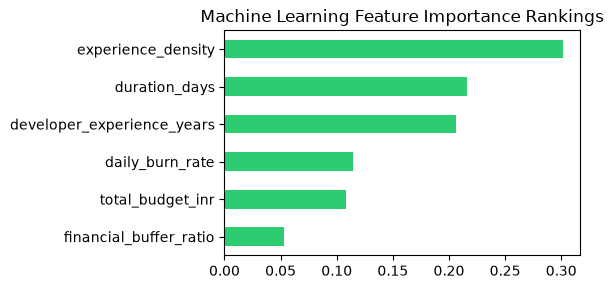

💾 Upgraded model successfully serialized at: 'models/model.pkl'


In [1]:
# %% [markdown]
# ## 🚀 Phase A: Enhanced Feature Engineering & Model Retraining

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

def train_advanced_risk_model(input_path="data/cleaned_data.csv", model_output_path="models/model.pkl"):
    print("\n--- Starting Advanced Feature Engineering & Training ---")
    
    if not os.path.exists(input_path):
        raise FileNotFoundError("Missing cleaned data! Please run the scrubbing cell first.")
        
    df = pd.read_csv(input_path)
    
    # 1. Feature Engineering Core Engine
    print("🧬 Computing advanced domain ratios...")
    
    # Feature 1: Daily Burn Rate (Financial Intensity)
    df["daily_burn_rate"] = df["total_budget_inr"] / df["duration_days"]
    
    # Feature 2: Expected Market Rate & Financial Buffer Ratio
    # Market standard baseline formula: duration * (500 + (experience * 400))
    expected_market_rate = df["duration_days"] * (500 + (df["developer_experience_years"] * 400))
    df["financial_buffer_ratio"] = df["total_budget_inr"] / expected_market_rate
    
    # Feature 3: Experience Density (Seniority relative to timeline compression)
    df["experience_density"] = df["developer_experience_years"] / df["duration_days"]
    
    # 2. Select the updated feature matrix
    feature_cols = [
        "developer_experience_years", "duration_days", "total_budget_inr",
        "daily_burn_rate", "financial_buffer_ratio", "experience_density"
    ]
    
    X = df[feature_cols]
    y = df["delivery_risk_label"]
    
    # 3. Train-Test Split (Stratified 80/20)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    
    # 4. Fit the upgraded Random Forest Classifier
    # Balanced class weights handle risk skew easily
    model = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42, class_weight="balanced")
    model.fit(X_train, y_train)
    
    # 5. Evaluate Upgraded Performance
    predictions = model.predict(X_test)
    print(f"\n🎯 Upgraded Accuracy: {accuracy_score(y_test, predictions) * 100:.2f}%")
    print("\nDetailed Performance Report:")
    print(classification_report(y_test, predictions, target_names=["Safe Track (0)", "High Risk (1)"]))
    
    # 6. Plot & Visualize Feature Importances
    fig, ax = plt.subplots(figsize=(6, 3))
    importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
    importances.plot(kind="barh", color="#2ecc71", ax=ax)
    ax.set_title("Machine Learning Feature Importance Rankings")
    plt.tight_layout()
    plt.show()
    
    # 7. Serialize the advanced model matrix to disk
    os.makedirs(os.path.dirname(model_output_path), exist_ok=True)
    with open(model_output_path, "wb") as f:
        pickle.dump(model, f)
    print(f"💾 Upgraded model successfully serialized at: '{model_output_path}'")
    
    # Update script version for environment compatibility
    write_advanced_production_script(model_output_path)
    return model

def write_advanced_production_script(model_output_path):
    """Updates src/train_model.py with the advanced feature engineering formulas."""
    script_content = f"""import os, pickle, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

def run_train():
    df = pd.read_csv("data/cleaned_data.csv")
    
    # Replicate engineered features exactly
    df["daily_burn_rate"] = df["total_budget_inr"] / df["duration_days"]
    expected_market_rate = df["duration_days"] * (500 + (df["developer_experience_years"] * 400))
    df["financial_buffer_ratio"] = df["total_budget_inr"] / expected_market_rate
    df["experience_density"] = df["developer_experience_years"] / df["duration_days"]
    
    feature_cols = ["developer_experience_years", "duration_days", "total_budget_inr", "daily_burn_rate", "financial_buffer_ratio", "experience_density"]
    X = df[feature_cols]
    y = df["delivery_risk_label"]
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=42, class_weight="balanced")
    model.fit(X_train, y_train)
    
    os.makedirs("models", exist_ok=True)
    with open("{model_output_path}", "wb") as f:
        pickle.dump(model, f)
    print("✅ Advanced Model trained via script execution.")

if __name__ == '__main__':
    run_train()
"""
    with open("src/train_model.py", "w", encoding="utf-8") as f:
        f.write(script_content.strip())

# Execute the advanced training pipeline
advanced_model = train_advanced_risk_model()